# 首次编译与预热：随机状态、计时边界和回合推进

目标：复现预热消耗随机状态的故障，理解首次编译为何必须在正式回合开始前完成，并复算真实延迟。输入为随机状态探针、真实推理源码、严格加载后的计时记录和已有视频；输出为状态恢复断言、历史延迟曲线及独立预热函数。

真实预热记录约17.85秒；严格加载后的稳态中位推理约897毫秒。预热消除首次准备成本，不会自动消除稳态推理与物理时序之间的差距。

## 使用方式与证据层次

每节先复现一个小型、可解释的错误，再展开真实源码、定位机制，最后核对历史设备记录与修复后的守卫。人工构造的参数树、状态探针和动作块只用于验证机制，不替代真实模型或成功率。默认不启动训练、模型服务或完整仿真。

真实模型检查须先选择已有匹配环境，设置 `AMD_DIAGNOSTICS_LIVE=1`，指定本地源码、配置、权重和独立输出目录；不下载资源，也不改原始实验目录。视频为已有完整回合，播放器直接内嵌数据。

In [1]:
from __future__ import annotations
from pathlib import Path
import json, os, sys, hashlib, dataclasses, tempfile, copy, time
import numpy as np
from IPython.display import display, Video
TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/amd_benchmarks").is_dir())
EVIDENCE = TOPIC / "notebooks/results"
SNAPSHOTS = TOPIC / "code/diagnostics_sources"
DIAG = EVIDENCE / "diagnostics"
RUN_LIVE_CHECKS = os.environ.get("AMD_DIAGNOSTICS_LIVE", "0") == "1"
for row in json.loads((DIAG / "source-manifest.json").read_text()):
    assert hashlib.sha256((TOPIC / row["file"]).read_bytes()).hexdigest() == row["sha256"]
print("源码与证据指纹通过；默认运行小型复现和历史记录复算，真实模型检查：", RUN_LIVE_CHECKS)


源码与证据指纹通过；默认运行小型复现和历史记录复算，真实模型检查： False


## 1. 定位真实推理：每次调用都会推进随机键

源码在每次推理前拆分随机键。预热若直接调用推理且不恢复状态，正式回合的第一份噪声就不同。下面显示原实现，不在默认模式下加载模型。

In [2]:
if False:  # Source reference; warmup is performed by the explicit wrapper below.
    @override
    def infer(self, obs: dict, *, noise: np.ndarray | None = None) -> dict:  # type: ignore[misc]
        # Make a copy since transformations may modify the inputs in place.
        inputs = jax.tree.map(lambda x: x, obs)
        inputs = self._input_transform(inputs)
        if not self._is_pytorch_model:
            # Make a batch and convert to jax.Array.
            inputs = jax.tree.map(lambda x: jnp.asarray(x)[np.newaxis, ...], inputs)
            self._rng, sample_rng_or_pytorch_device = jax.random.split(self._rng)
        else:
            # Convert inputs to PyTorch tensors and move to correct device
            import torch

            inputs = jax.tree.map(lambda x: torch.from_numpy(np.array(x)).to(self._pytorch_device)[None, ...], inputs)
            sample_rng_or_pytorch_device = self._pytorch_device

        # Prepare kwargs for sample_actions
        sample_kwargs = dict(self._sample_kwargs)
        if noise is not None:
            noise = torch.from_numpy(noise).to(self._pytorch_device) if self._is_pytorch_model else jnp.asarray(noise)

            if noise.ndim == 2:  # If noise is (action_horizon, action_dim), add batch dimension
                noise = noise[None, ...]  # Make it (1, action_horizon, action_dim)
            sample_kwargs["noise"] = noise

        observation = _model.Observation.from_dict(inputs)
        start_time = time.monotonic()
        outputs = {
            "state": inputs["state"],
            "actions": self._sample_actions(sample_rng_or_pytorch_device, observation, **sample_kwargs),
        }
        model_time = time.monotonic() - start_time
        if self._is_pytorch_model:
            outputs = jax.tree.map(lambda x: np.asarray(x[0, ...].detach().cpu()), outputs)
        else:
            outputs = jax.tree.map(lambda x: np.asarray(x[0, ...]), outputs)

        outputs = self._output_transform(outputs)
        outputs["policy_timing"] = {
            "infer_ms": model_time * 1000,
        }
        return outputs


## 2. 故障复现：额外预热改变下一次输出

状态探针只演示随机序列，不代表策略模型或任务成绩。两个新探针应有相同首次输出；其中一个多调用一次后，下一次输出会发生变化。

In [3]:
class StateProbe:
    def __init__(self): self._rng=0
    def infer(self,observation):
        value=np.random.default_rng(self._rng).normal(size=(30,22))
        self._rng+=1
        return {"actions":value}
reference=StateProbe().infer({})["actions"]
broken=StateProbe(); broken.infer({})
assert not np.array_equal(broken.infer({})["actions"],reference)
print("额外调用推进了随机状态。")


额外调用推进了随机状态。


## 3. 修复：预热后恢复状态，并验证异常路径

下面是课程的独立预热函数：先保存随机状态，再在正式回合之外推理，转换输出以等待设备完成，检查有限值，最后在所有退出路径恢复随机状态。该函数比历史服务中直接恢复随机键的片段增加了异常保护；历史记录保持原样。

In [4]:
def warmup_preserving_rng(policy,observation):
    """Compile on a real reset observation while preserving the policy random chain."""
    saved=copy.deepcopy(policy._rng)
    started=time.perf_counter()
    try:
        output=policy.infer(observation)
        actions=np.asarray(output["actions"])
        if not np.isfinite(actions).all():
            raise FloatingPointError("Warmup returned non-finite actions")
        return {"seconds":time.perf_counter()-started,"action_shape":list(actions.shape),"rng_restored":True}
    finally:
        policy._rng=saved

repaired=StateProbe(); report=warmup_preserving_rng(repaired,{})
assert repaired._rng==0
np.testing.assert_array_equal(repaired.infer({})["actions"],reference)
class FailingProbe(StateProbe):
    def infer(self,obs): self._rng+=1; raise RuntimeError("intentional warmup failure")
failed=FailingProbe()
try: warmup_preserving_rng(failed,{})
except RuntimeError as exc: print("预期异常：",exc)
else: raise AssertionError("Expected failure")
assert failed._rng==0
print("成功与异常路径都恢复状态；这里只验证机制，不报告模型预热时间。")


预期异常： intentional warmup failure
成功与异常路径都恢复状态；这里只验证机制，不报告模型预热时间。


In [5]:
class NonFiniteProbe(StateProbe):
    def infer(self,obs):
        self._rng+=1
        return {"actions":np.full((30,22),np.nan)}
nonfinite=NonFiniteProbe()
try: warmup_preserving_rng(nonfinite,{})
except FloatingPointError as exc: print("预期拒绝非有限动作：",exc)
else: raise AssertionError("Non-finite warmup must fail")
assert nonfinite._rng==0


预期拒绝非有限动作： Warmup returned non-finite actions


## 4. 从原始事件复算设备测量

严格计时事件来自正确加载、已预热起始权重的单回合诊断。下方重新计算首次调用与稳态中位数，并与原汇总核对。这份单回合不进入正式20种子成功率分母。

{'历史预热秒数': 17.84689265099587, '调用次数': 51, '稳态中位毫秒': 897.0902384899091}


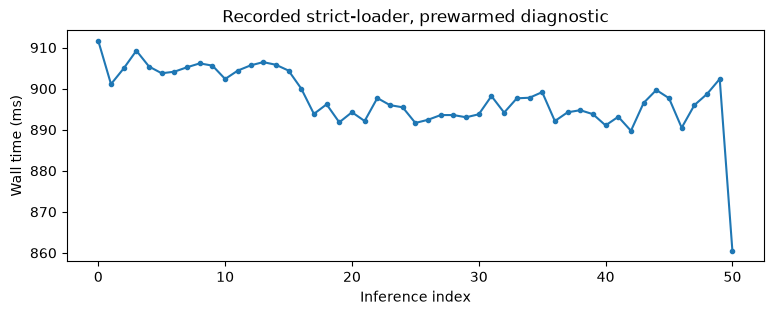

In [6]:
import statistics
import matplotlib.pyplot as plt
warmup=json.loads((EVIDENCE / "system/strict_latency_warmup.json").read_text())
events=[json.loads(line) for line in (DIAG / "strict-events.jsonl").read_text().splitlines()]
inferences=[row for row in events if row["event"]=="inference"]
latencies=[row["wall_ms"] for row in inferences]
summary=json.loads((EVIDENCE / "system/strict_latency_summary.json").read_text())
assert len(latencies)==summary["inference_count"]
median=statistics.median(latencies[1:])
assert np.isclose(median,summary["steady_inference_median_ms"])
print({"历史预热秒数":warmup["seconds"],"调用次数":len(latencies),"稳态中位毫秒":median})
fig,ax=plt.subplots(figsize=(9,3));ax.plot(latencies,marker=".");ax.set(xlabel="Inference index",ylabel="Wall time (ms)",title="Recorded strict-loader, prewarmed diagnostic");plt.show();plt.close(fig)


## 5. 可选：加载真实本地策略，使用真实重置观测预热

参数与加载篇相同；另设 `DEXJOCO_WARMUP_OBSERVATION` 为已有的真实重置观测序列化文件。观测应与正式任务相机、状态、指令和形状一致。下方不启动模拟器、不推进物理、不开始评估。若没有现成观测，先按18号的独立观测探针生成，不能用全零图像冒充真实重置输入。

In [7]:
def checkpoint_model_config(model, checkpoint):
    """Keep task adapters present in the checkpoint and reject silent parameter dropping."""
    metadata = json.loads((Path(checkpoint) / 'params/_METADATA').read_text())
    adapter_keys = [key for key in metadata['tree_metadata'] if 'lora_' in key]
    if not adapter_keys:
        model = dataclasses.replace(model,
            paligemma_variant=model.paligemma_variant.removesuffix('_lora'),
            action_expert_variant=model.action_expert_variant.removesuffix('_lora'))
    elif not all('lora' in value for value in [model.paligemma_variant, model.action_expert_variant]):
        raise ValueError('Checkpoint contains task adapters, but the model disables them.')

    class StrictCheckpointConfig(type(model)):
        def load(self, params, *, remove_extra_params=False):
            return super().load(params, remove_extra_params=False)

    checked = StrictCheckpointConfig(**{field.name: getattr(model, field.name)
                                       for field in dataclasses.fields(model) if field.init})
    return checked, {'adapter_tensor_count': len(adapter_keys),
                     'paligemma_variant': checked.paligemma_variant,
                     'action_expert_variant': checked.action_expert_variant,
                     'remove_extra_params': False, 'loader_contract': 'strict-adapters-v2'}


def load_existing_policy():
    """Load a cached checkpoint using the audited model contract in an isolated run root."""
    source = Path(os.environ["DEXJOCO_OPENPI_SOURCE"]).resolve()
    checkpoint = Path(os.environ["DEXJOCO_CHECKPOINT"]).resolve()
    config_path = Path(os.environ["DEXJOCO_DIAGNOSTIC_CONFIG"]).resolve()
    run_root = Path(os.environ["DEXJOCO_DIAG_RUN_ROOT"]).resolve()
    assert (source / "src/openpi").is_dir()
    assert (checkpoint / "params/_METADATA").is_file()
    c = json.loads(config_path.read_text())
    c["source_root"] = str(source.parent)
    c["run_root"] = str(run_root)
    run_root.mkdir(parents=True, exist_ok=False)
    previous_cwd, previous_path, previous_env = Path.cwd(), sys.path[:], dict(os.environ)
    old_download = sys.modules.get("openpi.shared.download")
    old_cached_asset = getattr(old_download, "maybe_download", None)
    download_module = None
    try:
        sys.path.insert(0, str(TOPIC / "code"))
        from amd_benchmarks.dexjoco import get_config
        cfg = get_config(c)
        from openpi.shared import download as download_module
        from openpi.policies import policy_config
        checked, audit = checkpoint_model_config(cfg.model, checkpoint)
        cfg = dataclasses.replace(cfg, model=checked)
        policy = policy_config.create_trained_policy(cfg, checkpoint)
        print(audit)
        return policy
    finally:
        download_module = sys.modules.get("openpi.shared.download", download_module)
        if download_module is not None:
            if old_cached_asset is not None:
                download_module.maybe_download = old_cached_asset
            else:
                import importlib
                importlib.reload(download_module)
        os.chdir(previous_cwd)
        sys.path[:] = previous_path
        os.environ.clear()
        os.environ.update(previous_env)


In [8]:
if RUN_LIVE_CHECKS:
    live_policy=load_existing_policy()
    from openpi_client import msgpack_numpy
    reset_observation=msgpack_numpy.unpackb(Path(os.environ["DEXJOCO_WARMUP_OBSERVATION"]).read_bytes())
    live_warmup=warmup_preserving_rng(live_policy,reset_observation)
    print(live_warmup)
else:
    print("真实策略预热关闭；已复算历史测量并验证随机状态守卫。")


真实策略预热关闭；已复算历史测量并验证随机状态守卫。


## 6. 历史冷启动回放：同时存在旧加载缺陷，仅用于观察停顿

此录像来自已有评估回合；模型、条件与种子按下方文件路径标注，不将画面作为单一修复因素的因果证明。

In [9]:
display(Video(str(EVIDENCE / 'dexjoco/cold_start_videos/base_seed_100.mp4'), embed=True))


## 7. 严格加载且预热后的官方异步回放：同任务种子100

此录像来自已有评估回合；模型、条件与种子按下方文件路径标注，不将画面作为单一修复因素的因果证明。

In [10]:
display(Video(str(EVIDENCE / 'dexjoco/videos/base_seed_100.mp4'), embed=True))


## 如何解释这两段录像

历史冷启动分组同时存在适配参数加载缺陷，不能把两段视频差异全部归因于预热。预热机制由随机状态守卫与计时边界验证，正式成绩读取严格加载后独立保存的两组20种子结果。稳态等待问题进入下一篇。